Elena Nathanielle Budiman Angkawi - 2702213764

Link video (youtube): https://youtu.be/bCGLu_h0_Ps?si=1kQaDP0kaDJrDzrN

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, classification_report

In [ ]:
# read dataset
df = pd.read_csv('ObesityDataSet2.csv')
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,24,1.58,65.29,yes,no,2.03,2.74,Sometimes,no,2.00,no,1.28,1.019,no,Public_Transportation,Overweight_Level_II
1,Male,23,1.65,66.00,no,no,3.00,3.00,Sometimes,no,2.00,no,3.00,0.000,no,Public_Transportation,Normal_Weight
2,Female,21,1.69,51.26,yes,yes,3.00,3.18,Frequently,no,1.91,no,0.48,0.625,no,Public_Transportation,Insufficient_Weight
3,Female,22,1.69,65.00,yes,yes,2.00,3.00,Sometimes,no,2.00,no,1.00,1.000,Sometimes,Public_Transportation,Normal_Weight
4,Female,23,1.61,82.64,yes,yes,2.96,1.00,Sometimes,no,2.98,no,0.74,2.000,Sometimes,Public_Transportation,Obesity_Type_I


# Pre Processing

Check first what we need to pre process. The **pipeline function is on the bottom**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1056 entries, 0 to 1055
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          1056 non-null   object 
 1   Age                             1056 non-null   object 
 2   Height                          1056 non-null   float64
 3   Weight                          1056 non-null   float64
 4   family_history_with_overweight  1056 non-null   object 
 5   FAVC                            1056 non-null   object 
 6   FCVC                            1019 non-null   float64
 7   NCP                             1056 non-null   float64
 8   CAEC                            1056 non-null   object 
 9   SMOKE                           1056 non-null   object 
 10  CH2O                            1056 non-null   float64
 11  SCC                             1056 non-null   object 
 12  FAF                             10

In [ ]:
df.isnull().sum()

,0
Gender,0
Age,0
Height,0
Weight,0
family_history_with_overweight,0
FAVC,0
FCVC,37
NCP,0
CAEC,0
SMOKE,0


There are 2 columns with null values

In [ ]:
df['SCC'].value_counts()

,count
SCC,
no,1001
yes,55


In [ ]:
df['MTRANS'].value_counts()

,count
MTRANS,
Public_Transportation,773
Automobile,216
Walking,29
Motorbike,8
Bike,4


We will later impute MTRANS with the mode, Public_Transportation

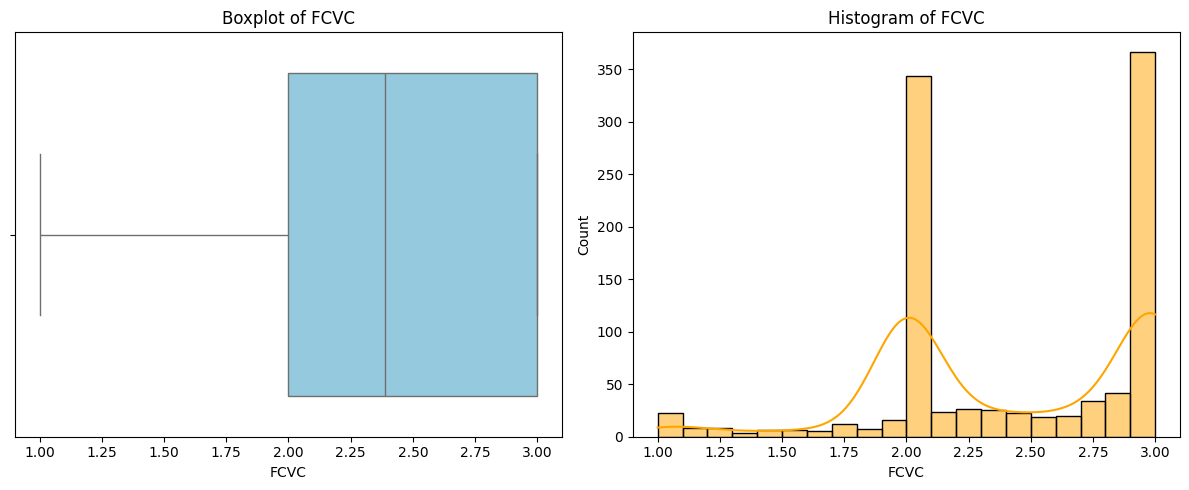

In [ ]:
# check boxplot and histogram of FCVC
plt.figure(figsize=(12,5))

# Boxplot
plt.subplot(1,2,1)
sns.boxplot(x=df['FCVC'], color='skyblue')
plt.title('Boxplot of FCVC')

# Histogram
plt.subplot(1,2,2)
sns.histplot(df['FCVC'], bins=20, kde=True, color='orange')
plt.title('Histogram of FCVC')

plt.tight_layout()
plt.show()


the distribution is not distributed normally so impute using median

**Task to Do in Preprocessing:**
1. Fill the missing value
2. Convert data types to the right one
3. Encode string (categorical) variables

In [ ]:
df['Age'].unique()

array(['24', '23', '21', '22', '26', '18', '25', '20', '32', '20 years',
       '19', '38', '34', '44', '39', '22 years', '41', '31', '17 years',
       '17', '29', '42', '27', '16', '25 years', '40', '21 years', '33',
       '30', '37', '35', '36', '15', '19 years', '28', '55', '46',
       '36 years', '26 years', '45', '33 years', '43', '51', '48',
       '23 years', '14'], dtype=object)

In [ ]:

# mapping dictionaries for encoding
gender_mapping = {'Male': 0, 'Female': 1}
yes_no_mapping = {'yes': 1, 'no': 0}
caec_mapping = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}
calc_mapping = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}
mtrans_mapping = {
    'Public_Transportation': 0,
    'Automobile': 1,
    'Walking': 2,
    'Motorbike': 3,
    'Bike': 4
}
nobeyesdad_mapping = {
    'Insufficient_Weight': 0,
    'Normal_Weight': 1,
    'Overweight_Level_I': 2,
    'Overweight_Level_II': 3,
    'Obesity_Type_I': 4,
    'Obesity_Type_II': 5,
    'Obesity_Type_III': 6
}


#PIPELINE
def preprocess_data(df):
    # fill missing val
    df['MTRANS'] = df['MTRANS'].fillna(df['MTRANS'].mode()[0])
    df['FCVC'] = df['FCVC'].fillna(df['FCVC'].median())

    # 2. remove 'years' text and convert to int
    df['Age'] = df['Age'].astype(str).str.replace(' years', '', regex=False).astype(int)

    # 3. encode categorical variables using mapping
    df['Gender'] = df['Gender'].map(gender_mapping)
    df['family_history_with_overweight'] = df['family_history_with_overweight'].map(yes_no_mapping)
    df['FAVC'] = df['FAVC'].map(yes_no_mapping)
    df['SCC'] = df['SCC'].map(yes_no_mapping)
    df['CAEC'] = df['CAEC'].map(caec_mapping)
    df['SMOKE'] = df['SMOKE'].map(yes_no_mapping)
    df['CALC'] = df['CALC'].map(calc_mapping)
    df['MTRANS'] = df['MTRANS'].map(mtrans_mapping)
    df['NObeyesdad'] = df['NObeyesdad'].map(nobeyesdad_mapping)

    return df


In [ ]:
df = preprocess_data(df)

# Modelling + Evaluation

In [ ]:
# split X and y
X = df.drop('NObeyesdad', axis=1)
y = df['NObeyesdad']

# split train and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

We can see below that it's better for **XGBoost model**, so we'll choose that model to import as pickle

## Random Forest

In [ ]:
# train model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [ ]:
# evaluate model
print("\nRandom Forest Evaluation Metrics:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision (macro): {precision_score(y_test, y_pred_rf, average='macro'):.4f}")
print(f"Recall (macro): {recall_score(y_test, y_pred_rf, average='macro'):.4f}")
print(f"F1-Score (macro): {f1_score(y_test, y_pred_rf, average='macro'):.4f}")


Random Forest Evaluation Metrics:
Accuracy: 0.9057
Precision (macro): 0.9026
Recall (macro): 0.9014
F1-Score (macro): 0.9016


In [ ]:
# classification report
print("\nClassification Report for Random Forest:")
print(classification_report(y_test, y_pred_rf))


Classification Report for Random Forest:
              precision    recall  f1-score   support

           0       0.92      0.89      0.91        27
           1       0.82      0.86      0.84        36
           2       0.81      0.81      0.81        26
           3       0.83      0.87      0.85        23
           4       0.97      0.91      0.94        34
           5       1.00      0.97      0.99        34
           6       0.97      1.00      0.98        32

    accuracy                           0.91       212
   macro avg       0.90      0.90      0.90       212
weighted avg       0.91      0.91      0.91       212



## XGBoost

In [ ]:
# train model
xgb_model = XGBClassifier(objective='multi:softmax' if len(y.unique()) > 2 else 'binary:logistic',
                          num_class=len(y.unique()),
                          eval_metric='mlogloss' if len(y.unique()) > 2 else 'logloss',
                          use_label_encoder=False,
                          n_estimators=100,
                          learning_rate=0.1,
                          random_state=42)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [06:16:51] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


In [ ]:
print("\nXGBoost Evaluation Metrics:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"Precision (macro): {precision_score(y_test, y_pred_xgb, average='macro'):.4f}")
print(f"Recall (macro): {recall_score(y_test, y_pred_xgb, average='macro'):.4f}")
print(f"F1-Score (macro): {f1_score(y_test, y_pred_xgb, average='macro'):.4f}")


XGBoost Evaluation Metrics:
Accuracy: 0.9528
Precision (macro): 0.9534
Recall (macro): 0.9483
F1-Score (macro): 0.9498


In [ ]:
# classification report
print("\nClassification Report for XGBoost:")
print(classification_report(y_test, y_pred_xgb))


Classification Report for XGBoost:
              precision    recall  f1-score   support

           0       1.00      0.89      0.94        27
           1       0.92      0.97      0.95        36
           2       0.83      0.92      0.87        26
           3       0.95      0.91      0.93        23
           4       0.97      0.97      0.97        34
           5       1.00      0.97      0.99        34
           6       1.00      1.00      1.00        32

    accuracy                           0.95       212
   macro avg       0.95      0.95      0.95       212
weighted avg       0.96      0.95      0.95       212



# Import XGBoost as pickle

Dari performa yang sudah ditunjukkan, model yang akan kita pilih yaitu **XGBoost** dengan keseluruhan metriks yang absolut lebih tinggi dibandingkan Random Forest.

In [ ]:
import pickle

In [ ]:
with open('xgb_model.pkl', 'wb') as file:
    pickle.dump(xgb_model, file)